In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

In [14]:
import glob
import os
import kagglehub
import pandas as pd

# 1. Baixa a versão mais recente do dataset do Kaggle
path = kagglehub.dataset_download("alanvourch/tmdb-movies-daily-updates")

# 2. Localiza automaticamente o arquivo .csv dentro da pasta baixada
csv_path = glob.glob(os.path.join(path, "*.csv"))[0]
print("Carregando:", csv_path)

# 3. Lê o CSV (low_memory=False evita avisos de tipos mistos em colunas grandes)
df = pd.read_csv(csv_path, low_memory=False)
print(f"Shape: {df.shape}")
df.head()

Carregando: C:\Users\Aline M\.cache\kagglehub\datasets\alanvourch\tmdb-movies-daily-updates\versions\1072\TMDB_all_movies.csv
Shape: (1278466, 30)


,id,title,vote_average,vote_count,status,release_date,revenue,runtime,budget,imdb_id,...,director,director_of_photography,writers,producers,music_composer,imdb_rating,imdb_votes,poster_path,keywords,certification_us
0,2,Ariel,7.100,382.0,Released,1988-10-21,0.0,73.0,0.0,tt0094675,...,Aki Kaurismäki,Timo Salminen,Aki Kaurismäki,Aki Kaurismäki,NaN,7.4,10111.0,/ojDg0PGvs6R9xYFodRct2kdI6wC.jpg,"prison|underdog|helsinki, finland|factory work...",NaN
1,3,Shadows in Paradise,7.300,457.0,Released,1986-10-17,0.0,74.0,0.0,tt0092149,...,Aki Kaurismäki,Timo Salminen,Aki Kaurismäki,Mika Kaurismäki,NaN,7.4,8938.0,/nj01hspawPof0mJmlgfjuLyJuRN.jpg,"helsinki, finland|salesclerk|garbage",NR
2,5,Four Rooms,5.900,2942.0,Released,1995-12-09,4257354.0,98.0,4000000.0,tt0113101,...,"Allison Anders, Alexandre Rockwell, Robert Rod...","Rodrigo García, Guillermo Navarro, Phil Parmet...","Allison Anders, Alexandre Rockwell, Robert Rod...","Lawrence Bender, Quentin Tarantino, Alexandre ...",Combustible Edison,6.7,118168.0,/75aHn1NOYXh4M7L5shoeQ6NGykP.jpg,hotel|new year's eve|witch|bet|sperm|hotel roo...,R
3,6,Judgment Night,6.455,397.0,Released,1993-10-15,12136938.0,110.0,21000000.0,tt0107286,...,Stephen Hopkins,Peter Levy,"Lewis Colick, Jere Cunningham","Gene Levy, Marilyn Vance, Lloyd Segan",Alan Silvestri,6.6,21514.0,/3rvvpS9YPM5HB2f4HYiNiJVtdam.jpg,"drug dealer|chicago, illinois|escape|one night...",R
4,8,Life in Loops (A Megacities RMX),7.300,34.0,Released,2006-01-01,0.0,80.0,42000.0,tt0825671,...,Timo Novotny,Wolfgang Thaler,"Michael Glawogger, Timo Novotny","Timo Novotny, Ulrich Gehmacher",NaN,8.1,285.0,/7ln81BRnPR2wqxuITZxEciCe1lc.jpg,megacities,NaN


In [15]:
df.shape

(1278466, 30)

In [16]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1278466 entries, 0 to 1278465
Data columns (total 30 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   id                       1278466 non-null  int64  
 1   title                    1278452 non-null  str    
 2   vote_average             1278466 non-null  float64
 3   vote_count               1278466 non-null  float64
 4   status                   1278466 non-null  str    
 5   release_date             1139874 non-null  str    
 6   revenue                  1278466 non-null  float64
 7   runtime                  1278466 non-null  float64
 8   budget                   1278466 non-null  float64
 9   imdb_id                  700632 non-null   str    
 10  original_language        1278466 non-null  str    
 11  original_title           1278452 non-null  str    
 12  overview                 1081581 non-null  str    
 13  popularity               1278466 non-null  float64
 1

Descrição das colunas:

id: Identicador único para cada filme

title: Título oficial do filme

vote_average: Nota média do filme em uma escala de 0 a 10

vote_count: Número de votos que contribuiram para a nota do filme

Status: status atual do filme(em andamento ou já lançado)

release_date: data oficial do lançamento do filme

revenue: Receita(Arrecadação do filme nas bilheterias)

runtime: Tempo de duração do filme em minutos

budget: Orçamento destinado à produção do filme

imdb_id: Identificador do filme no IMDb

original_language: Linguagem em que o filme foi originalmente produzido

original_title: o título do filme na língua original

overview: resumo do enredo do filme

popularity: Pontuação de popularidade do filme no TMDB

tagline: slogan oficial do filme

genres: categorias de gêneros que o filme pertence

production_companies: Companias envolvidas na produção do filme

production_countries: Países onde o filme foi produzido

spoken_languages: Línguas faladas no filme

cast: elenco todo

director: todos os diretores

director_of_photography: todos os diretores de fotografia

writers: todos os escritores

producers: produtores e produtores executivos

music_composer: quem escreveu a música

imdb_rating: Avaliação IMDB

imdb_votes: Contagem de votos IMDB

poster_path: Caminho para a imagem do pôster do filme

keyworlds: Palavras que descrevem o filme

certification_us: Indica a classificação indicativa do filme nos Estados Unidos

In [17]:
df.describe()

,id,vote_average,vote_count,revenue,runtime,budget,popularity,imdb_rating,imdb_votes
count,1.278466e+06,1.278466e+06,1.278466e+06,1.278466e+06,1.278466e+06,1.278466e+06,1.278466e+06,485182.000000,4.851820e+05
mean,9.193933e+05,2.060084e+00,2.242718e+01,6.699338e+05,4.324474e+01,2.694374e+05,7.469959e-01,6.246456,2.791108e+03
std,5.208117e+05,3.141171e+00,3.706971e+02,1.674162e+07,5.387706e+01,4.786781e+06,2.384734e+00,1.325549,3.268521e+04
min,2.000000e+00,0.000000e+00,0.000000e+00,-1.200000e+01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000,5.000000e+00
25%,4.703062e+05,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+00,0.000000e+00,9.790000e-02,5.500000,2.000000e+01
50%,9.109790e+05,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+01,0.000000e+00,6.000000e-01,6.400000,5.800000e+01
75%,1.375168e+06,5.000000e+00,1.000000e+00,0.000000e+00,8.400000e+01,0.000000e+00,9.032000e-01,7.100000,2.590000e+02
max,1.841664e+06,1.000000e+01,4.200100e+04,2.942661e+09,1.440000e+04,1.000000e+09,1.957278e+03,10.000000,3.267800e+06


In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum().sort_values()*100/len(df))

Colunas com ausentes: ['title', 'release_date', 'imdb_id', 'original_title', 'overview', 'tagline', 'genres', 'production_companies', 'production_countries', 'spoken_languages', 'cast', 'director', 'director_of_photography', 'writers', 'producers', 'music_composer', 'imdb_rating', 'imdb_votes', 'poster_path', 'keywords', 'certification_us']
title                       0.001095
original_title              0.001095
release_date               10.840492
overview                   15.400097
director                   16.010281
poster_path                23.857185
genres                     26.297062
cast                       31.538265
spoken_languages           36.261191
production_countries       37.146314
imdb_id                    45.197448
writers                    49.120665
production_companies       51.454869
imdb_rating                62.049675
imdb_votes                 62.049675
producers                  65.271896
keywords                   71.450864
director_of_photography    7

* Os dados foram coletado da API do TMDB(The Movie Database)

Visualização dos dados ausentes em forma de gráfico

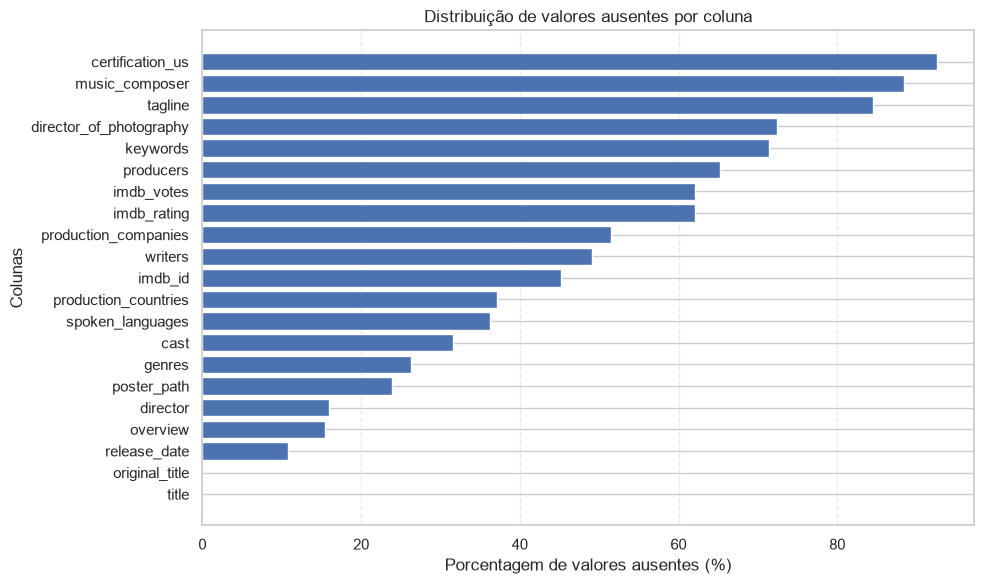

In [20]:
# Calcula a porcentagem de valores ausentes por coluna
ausentes = df.isna().sum()
percentual_ausentes = (ausentes / len(df)) * 100

# Mantém apenas as colunas que possuem valores ausentes
percentual_ausentes = percentual_ausentes[percentual_ausentes > 0]

# Ordena os valores
percentual_ausentes = percentual_ausentes.sort_values()

# Cria o gráfico
plt.figure(figsize=(10, 6))

plt.barh(
    percentual_ausentes.index,
    percentual_ausentes.values
)

plt.xlabel("Porcentagem de valores ausentes (%)")
plt.ylabel("Colunas")
plt.title("Distribuição de valores ausentes por coluna")

plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

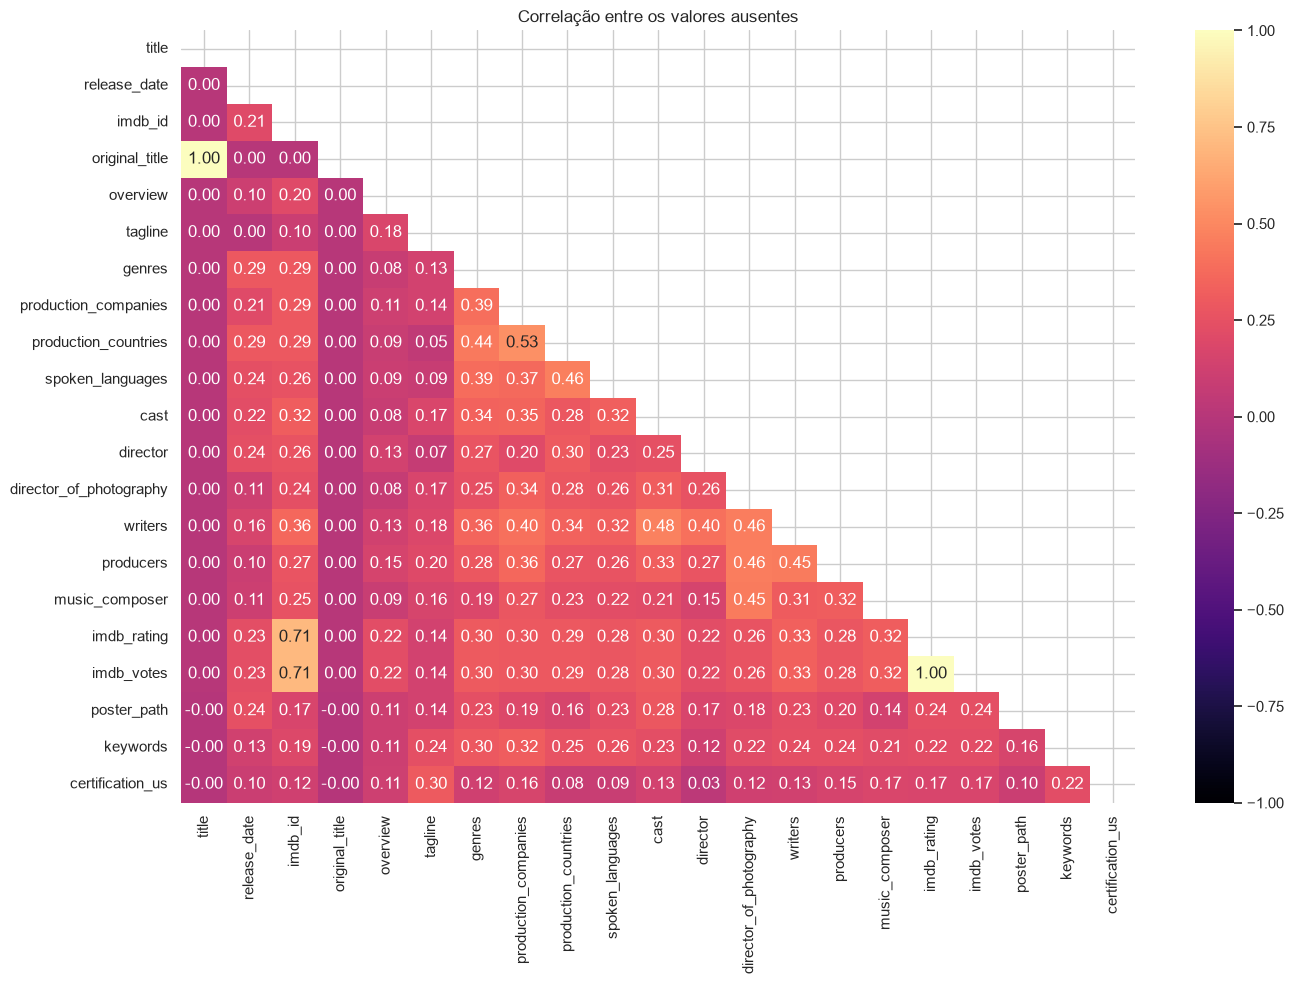

In [21]:
# Verifica quais valores estão ausentes
dados_ausentes = df[cols_com_ausentes].isna()

# Calcula a correlação entre as ausências
correlacao_ausentes = dados_ausentes.corr()

# Cria máscara para ocultar o triângulo superior
mascara = np.triu(np.ones_like(correlacao_ausentes, dtype=bool))

# Cria o gráfico
fig, ax = plt.subplots(figsize=(14, 10))

sns.heatmap(
    correlacao_ausentes,
    mask=mascara,
    annot=True,
    fmt=".2f",
    cmap="magma",
    vmin=-1,
    vmax=1,
    ax=ax
)

ax.set_title("Correlação entre os valores ausentes")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

* Original_titlw e title: 1.0
* Imdb_votes e imdb_rating: 1.00
* Imdb_rating e imdb_id: 0.71
* Imdb_votes e imdb_id: 0.71


In [22]:
VARS_QUANT = [
    "vote_average",
    "vote_count",
    "revenue",
    "runtime",
    "budget",
    "popularity",
    "imdb_rating",
    "imdb_votes"
]

VARS_QUALI = [
    "status",
    "release_date",
    "original_language",
    "genres",
    "production_companies",
    "production_countries",
    "spoken_languages",
    "cast",
    "director",
    "director_of_photography",
    "writers",
    "producers",
    "music_composer",
    "keywords",
    "certification_us"
]

VARS_QUALI_ALTA=["id","imdb_id", "title","original_title","overview","tagline", "poster_path"]

In [23]:
desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
vote_average,2.06,0.00,3.14,0.00,10.00,1.10,-0.35
vote_count,22.43,0.00,370.70,0.00,42001.00,41.61,2422.17
revenue,669933.77,0.00,16741624.22,-12.00,2942661253.00,59.96,5576.76
runtime,43.24,20.00,53.88,0.00,14400.00,44.59,10028.63
budget,269437.36,0.00,4786780.98,0.00,999999999.00,42.91,3646.23
popularity,0.75,0.60,2.38,0.00,1957.28,457.29,357668.37
imdb_rating,6.25,6.40,1.33,1.00,10.00,-0.42,0.36
imdb_votes,2791.11,58.00,32685.21,5.00,3267800.00,34.23,1831.74


As variáveis: vote_average, vote_count, revenue, runtime, budget, popularity, imdb_votes possuem skewness acima de 1

As variáveis: vote_count, revenue, runtime, budget, popularity, imdb_votes possuem kurtosis acima de 2



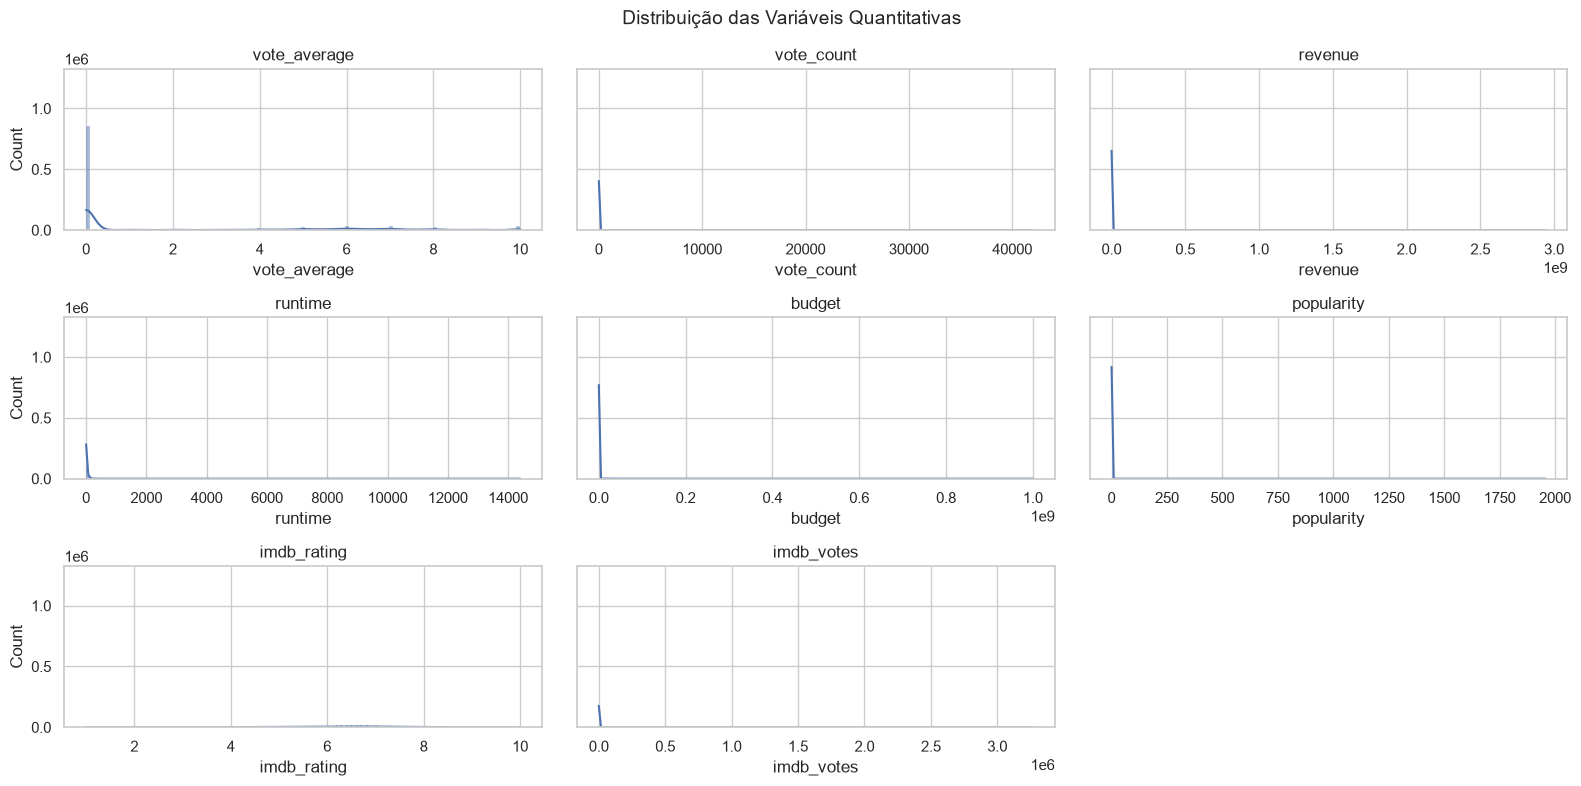

In [24]:
fig, axes = plt.subplots(3, 3, figsize=(16, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, kde=True, color="#4C72B0", ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas", fontsize=14)
plt.tight_layout()
plt.show()

Melhorando a visualização dos gráficos

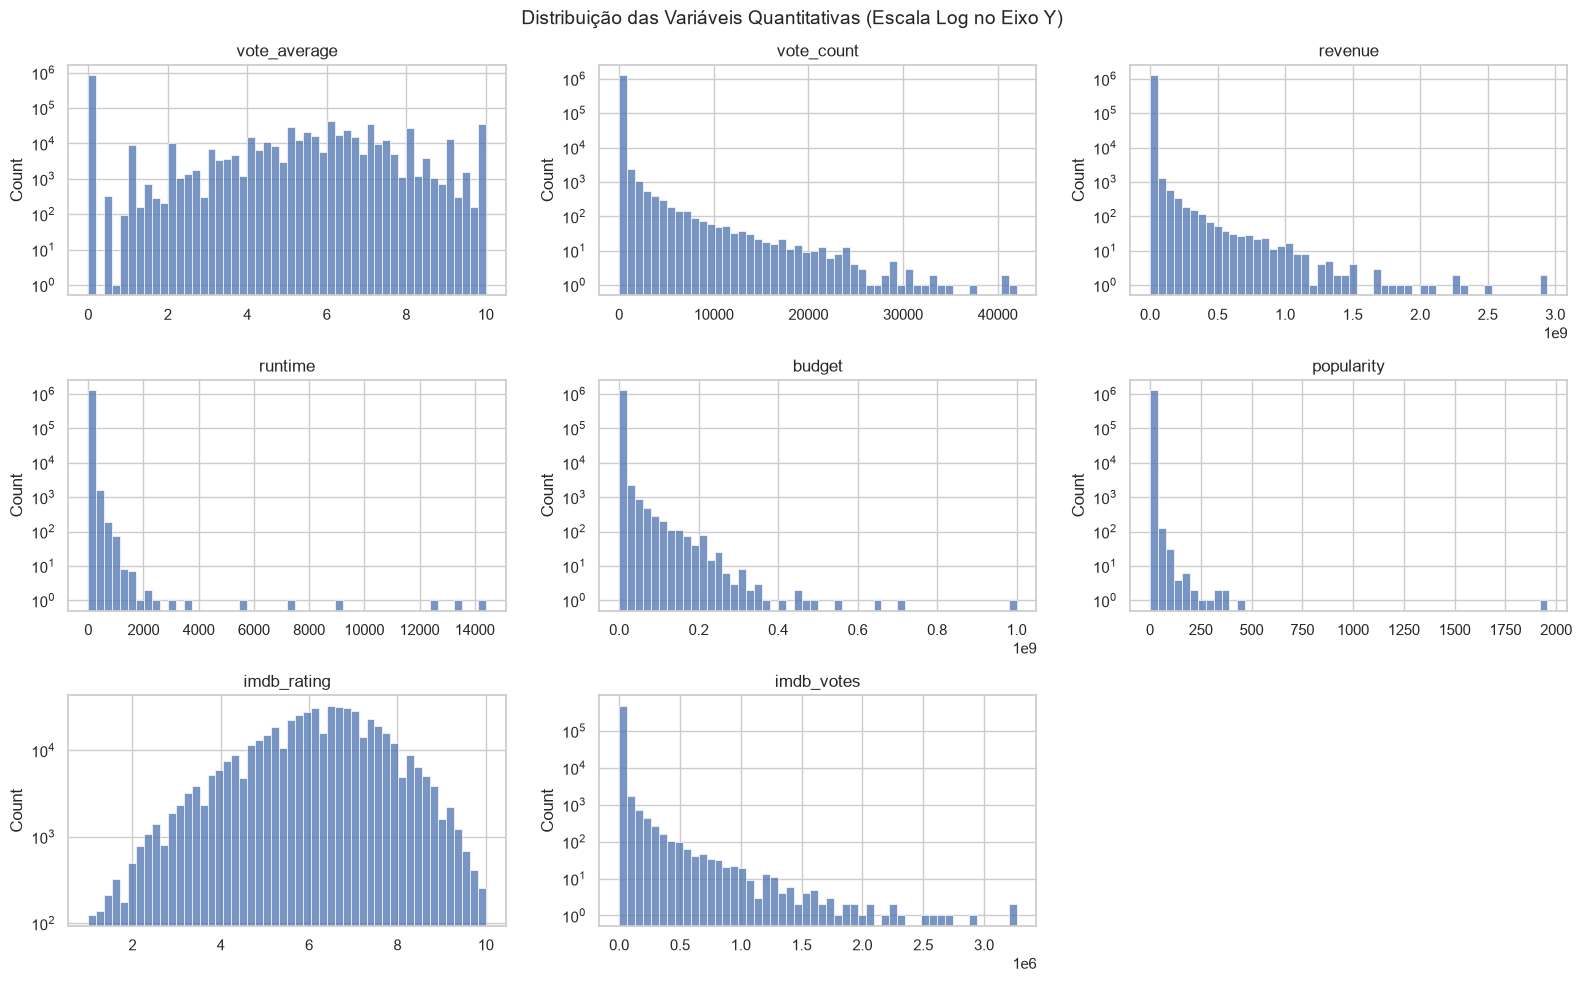

In [25]:
fig, axes = plt.subplots(3, 3, figsize=(16, 10)) # Removido sharey=True
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, bins=50, color="#4C72B0", ax=axes[i])
    axes[i].set_yscale("log") # Escala log no eixo Y para lidar com o pico de zeros
    axes[i].set_title(col)
    axes[i].set_xlabel("") # Remove label redundante abaixo de cada gráfico

for ax in axes[len(VARS_QUANT):]:
    ax.axis("off")

fig.suptitle("Distribuição das Variáveis Quantitativas (Escala Log no Eixo Y)", fontsize=14)
plt.tight_layout()
plt.show()

In [26]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

,var,std,IQR
vote_average,9.870000e+00,3.14,5.00
vote_count,1.374164e+05,370.70,1.00
revenue,2.802820e+14,16741624.22,0.00
runtime,2.902740e+03,53.88,82.00
budget,2.291327e+13,4786780.98,0.00
popularity,5.690000e+00,2.38,0.81
imdb_rating,1.760000e+00,1.33,1.60
imdb_votes,1.068323e+09,32685.21,239.00


In [27]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))


--- status ---
                 absoluta  relativa
status                             
Released          1254603     0.981
Post Production      7405     0.006
Planned              7081     0.006
In Production        6870     0.005
Rumored              1256     0.001
Canceled             1251     0.001

--- release_date ---
              absoluta  relativa
release_date                    
2006-01-01        3784     0.003
2013-01-01        3662     0.003
2010-01-01        3604     0.003
2011-01-01        3582     0.003
2012-01-01        3546     0.003
...                ...       ...
2027-11-21           1     0.000
2029-06-15           1     0.000
1902-02-21           1     0.000
2028-03-02           1     0.000
1902-02-19           1     0.000

[44600 rows x 2 columns]

--- original_language ---
                   absoluta  relativa
original_language                    
en                   614774     0.481
fr                    82276     0.064
es                    80985     0.063
ja

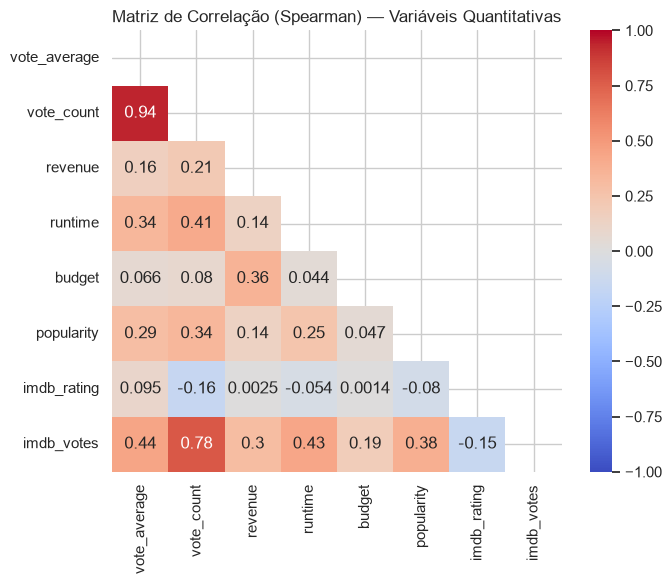

In [28]:
# Calcula a correlação de Spearman
correlacao = df[VARS_QUANT].corr(method="spearman")

# Cria máscara para ocultar o triângulo superior
mascara = np.triu(np.ones_like(correlacao, dtype=bool))

plt.figure(figsize=(7, 6))

sns.heatmap(
    correlacao,
    mask=mascara,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Matriz de Correlação (Spearman) — Variáveis Quantitativas")
plt.tight_layout()
plt.show()

vote_count e vote_average = 0.94

imdb_votes e vote_count = 0.78


In [29]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
vote_average,-7.50,12.50,0.0
vote_count,-1.50,2.50,221897.0
revenue,0.00,0.00,29348.0
runtime,-121.00,207.00,5442.0
budget,0.00,0.00,87935.0
popularity,-1.11,2.11,69675.0
imdb_rating,3.10,9.50,10734.0
imdb_votes,-338.50,617.50,75536.0


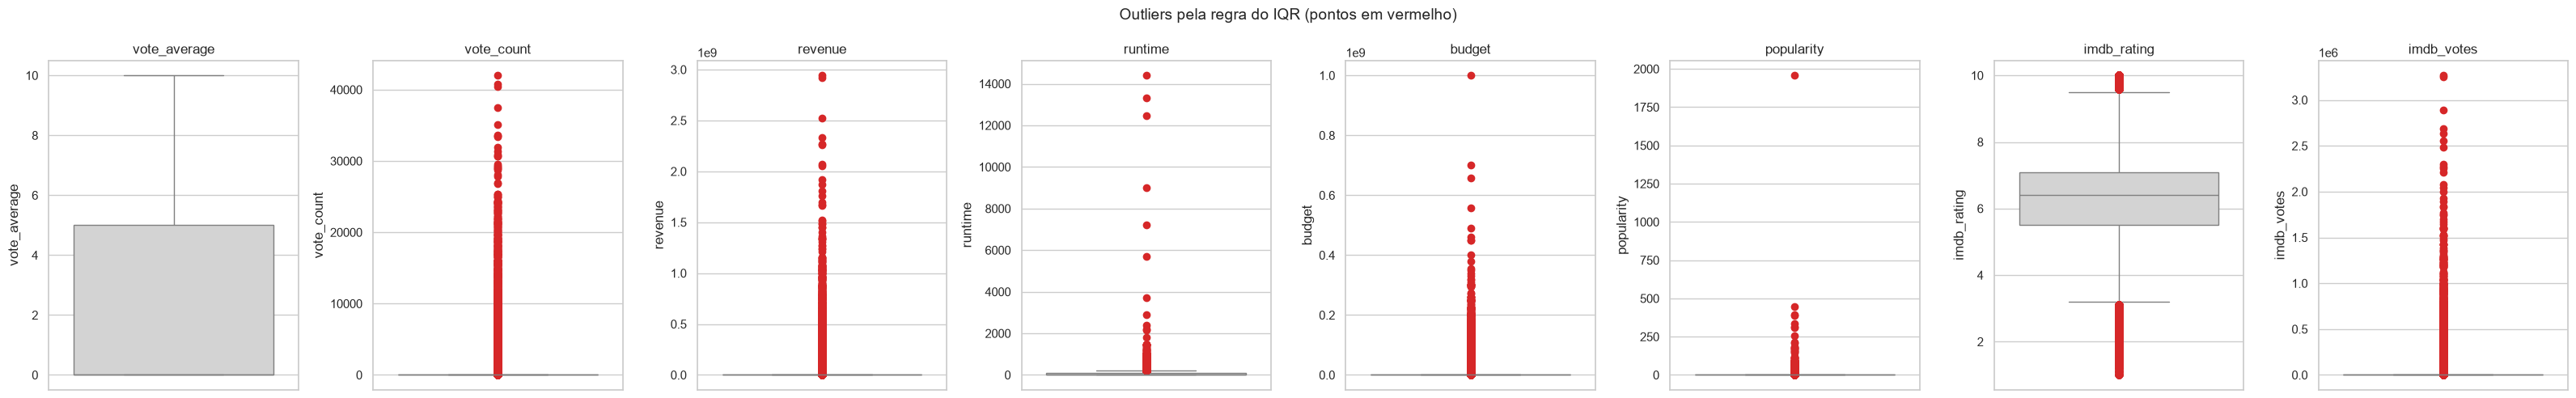

In [30]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(4 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
                ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

Como o grafo vai seguir essas regras:

Vértices: filmes

Direção: do filme mais antigo -> filme mais recente

Conexão: Se houver atores em comum

Peso: imdb_rating do mais atual - imdb_rating do mais antigo

Decidimos remover as linhas que possuem essas colunas em branco: title, release_date, imdb_rating, cast

Decidimos remover as colunas: music_composer, tagline e certification_us por terem uma porcentagem elevada de dados ausentes e não influenciarem na nossa lógica escolhida para grafos
